In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.chdir("/content/drive/MyDrive/MP-PCA")
print(os.getcwd())
print(os.listdir("denoised"))

/content/drive/MyDrive/MP-PCA
['combined_dipy_10.mat', 'combined_noclip_10.mat', 'combined_dipy_30.mat', 'combined_noclip_30.mat', 'combined_dipy_50.mat', 'combined_noclip_50.mat']


In [3]:
import scipy.io as sio
import numpy as np

# DIPY 결과
dipy_mat = sio.loadmat(
    "denoised/combined_dipy_10.mat"
)

dipy_result = dipy_mat["combined_denoised"]

print("===== DIPY =====")
print("shape :", dipy_result.shape)
print("dtype :", dipy_result.dtype)
print("min :", dipy_result.min())
print("max :", dipy_result.max())
print("NaN :", np.isnan(dipy_result).sum())
print("음수 개수 :", np.sum(dipy_result < 0))

===== DIPY =====
shape : (256, 224, 176, 12)
dtype : float32
min : 0.0
max : 15.232066
NaN : 0
음수 개수 : 0


In [4]:
noclip_mat = sio.loadmat(
    "denoised/combined_noclip_10.mat"
)

noclip_result = noclip_mat["combined_denoised"]

print("===== NO-CLIP =====")
print("shape :", noclip_result.shape)
print("dtype :", noclip_result.dtype)
print("min :", noclip_result.min())
print("max :", noclip_result.max())
print("NaN :", np.isnan(noclip_result).sum())
print("음수 개수 :", np.sum(noclip_result < 0))

===== NO-CLIP =====
shape : (256, 224, 176, 12)
dtype : float32
min : -13.994086
max : 15.232066
NaN : 0
음수 개수 : 6058949


In [5]:
import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

os.chdir("/content/drive/MyDrive/MP-PCA")

# 원본
mat = sio.loadmat("meas_gre_dir1.mat")
meas_gre = mat["meas_gre"]

# 10% noisy
noise_mat = sio.loadmat(
    "noisy_data/noisy_meas_gre_dir1_10.mat"
)

noisy_real = noise_mat["noisy_real"]
noisy_imag = noise_mat["noisy_imag"]

noisy_complex = noisy_real + 1j * noisy_imag

# DIPY Combined
dipy_mat = sio.loadmat(
    "denoised/combined_dipy_10.mat"
)
dipy_combined = dipy_mat["combined_denoised"]

# No-clip Combined
noclip_mat = sio.loadmat(
    "denoised/combined_noclip_10.mat"
)
noclip_combined = noclip_mat["combined_denoised"]

print("Original :", meas_gre.shape)
print("Noisy    :", noisy_complex.shape)
print("DIPY     :", dipy_combined.shape)
print("No-clip  :", noclip_combined.shape)

Original : (256, 224, 176, 6)
Noisy    : (256, 224, 176, 6)
DIPY     : (256, 224, 176, 12)
No-clip  : (256, 224, 176, 12)


In [6]:
N_ECHO = 6

# DIPY
dipy_real = dipy_combined[..., :N_ECHO]
dipy_imag = dipy_combined[..., N_ECHO:]

dipy_complex = dipy_real + 1j * dipy_imag


# No-clip
noclip_real = noclip_combined[..., :N_ECHO]
noclip_imag = noclip_combined[..., N_ECHO:]

noclip_complex = noclip_real + 1j * noclip_imag

print("DIPY complex   :", dipy_complex.shape)
print("No-clip complex:", noclip_complex.shape)

DIPY complex   : (256, 224, 176, 6)
No-clip complex: (256, 224, 176, 6)


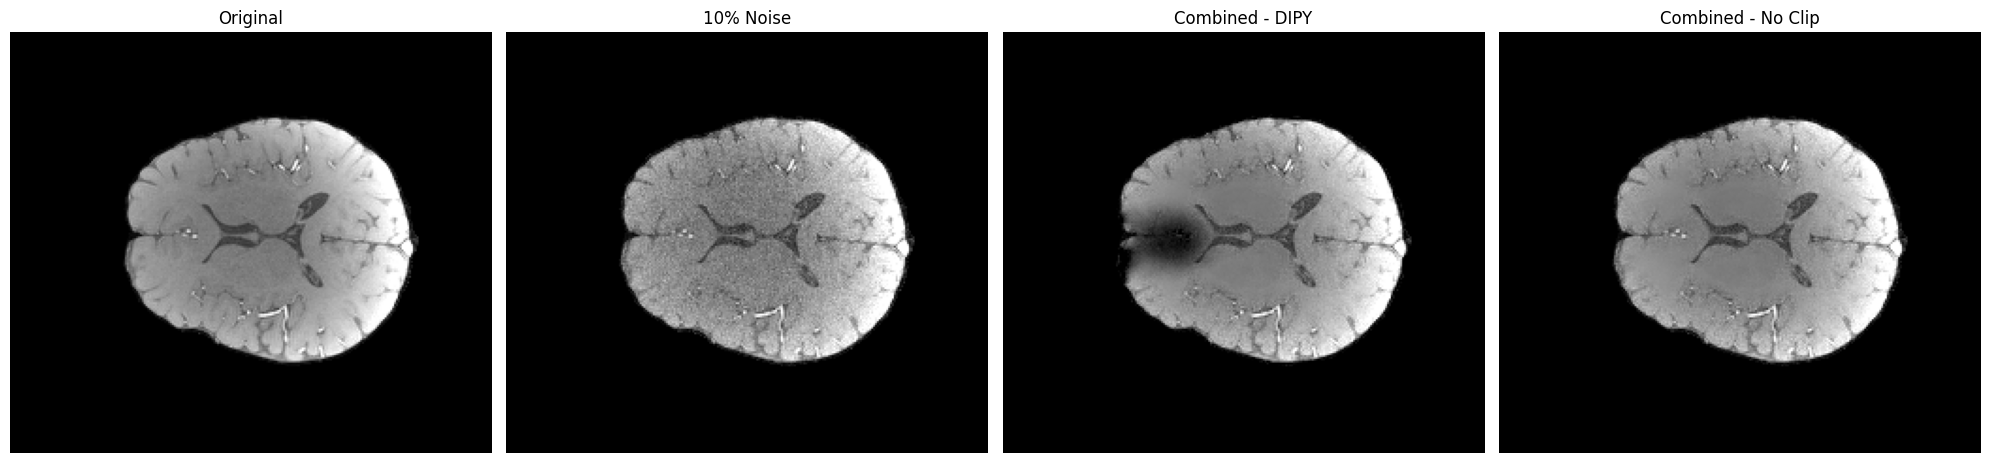

In [7]:
echo = 0
z = meas_gre.shape[2] // 2

original_mag = np.abs(meas_gre)
noisy_mag = np.abs(noisy_complex)
dipy_mag = np.abs(dipy_complex)
noclip_mag = np.abs(noclip_complex)

# 동일한 밝기 범위 사용
vmin = np.percentile(original_mag[:, :, z, echo], 1)
vmax = np.percentile(original_mag[:, :, z, echo], 99)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(
    original_mag[:, :, z, echo].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
axes[0].set_title("Original")

axes[1].imshow(
    noisy_mag[:, :, z, echo].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
axes[1].set_title("10% Noise")

axes[2].imshow(
    dipy_mag[:, :, z, echo].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
axes[2].set_title("Combined - DIPY")

axes[3].imshow(
    noclip_mag[:, :, z, echo].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
axes[3].set_title("Combined - No Clip")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

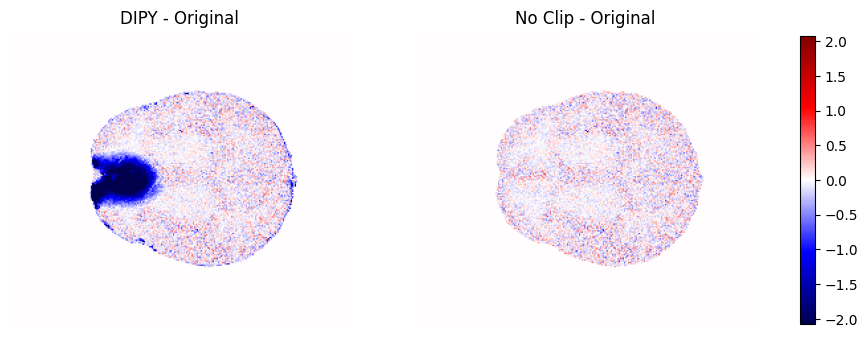

In [8]:
dipy_error = dipy_mag[:, :, z, echo] - original_mag[:, :, z, echo]
noclip_error = noclip_mag[:, :, z, echo] - original_mag[:, :, z, echo]

error_max = max(
    np.percentile(np.abs(dipy_error), 99),
    np.percentile(np.abs(noclip_error), 99)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(
    dipy_error.T,
    cmap="seismic",
    origin="lower",
    vmin=-error_max,
    vmax=error_max
)
axes[0].set_title("DIPY - Original")
axes[0].axis("off")

im2 = axes[1].imshow(
    noclip_error.T,
    cmap="seismic",
    origin="lower",
    vmin=-error_max,
    vmax=error_max
)
axes[1].set_title("No Clip - Original")
axes[1].axis("off")

plt.colorbar(im2, ax=axes.ravel().tolist(), shrink=0.75)
plt.show()

In [9]:
import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

os.chdir("/content/drive/MyDrive/MP-PCA")

mat = sio.loadmat("meas_gre_dir1.mat")
meas_gre = mat["meas_gre"]

noise_levels = [10, 30, 50]

data = {}

for level in noise_levels:

    noise_mat = sio.loadmat(
        f"noisy_data/noisy_meas_gre_dir1_{level}.mat"
    )

    noisy_real = noise_mat["noisy_real"]
    noisy_imag = noise_mat["noisy_imag"]

    noisy_complex = noisy_real + 1j * noisy_imag

    dipy_mat = sio.loadmat(
        f"denoised/combined_dipy_{level}.mat"
    )

    noclip_mat = sio.loadmat(
        f"denoised/combined_noclip_{level}.mat"
    )

    dipy_combined = dipy_mat["combined_denoised"]
    noclip_combined = noclip_mat["combined_denoised"]

    dipy_complex = (
        dipy_combined[..., :6]
        + 1j * dipy_combined[..., 6:]
    )

    noclip_complex = (
        noclip_combined[..., :6]
        + 1j * noclip_combined[..., 6:]
    )

    data[level] = {
        "noisy": noisy_complex,
        "dipy": dipy_complex,
        "noclip": noclip_complex
    }

print("10/30/50 로드 완료")

10/30/50 로드 완료


10% 처리 중...
30% 처리 중...
50% 처리 중...
이미지 저장 완료:
visualization/combined_compare_echo1_slice88_10_30_50.png


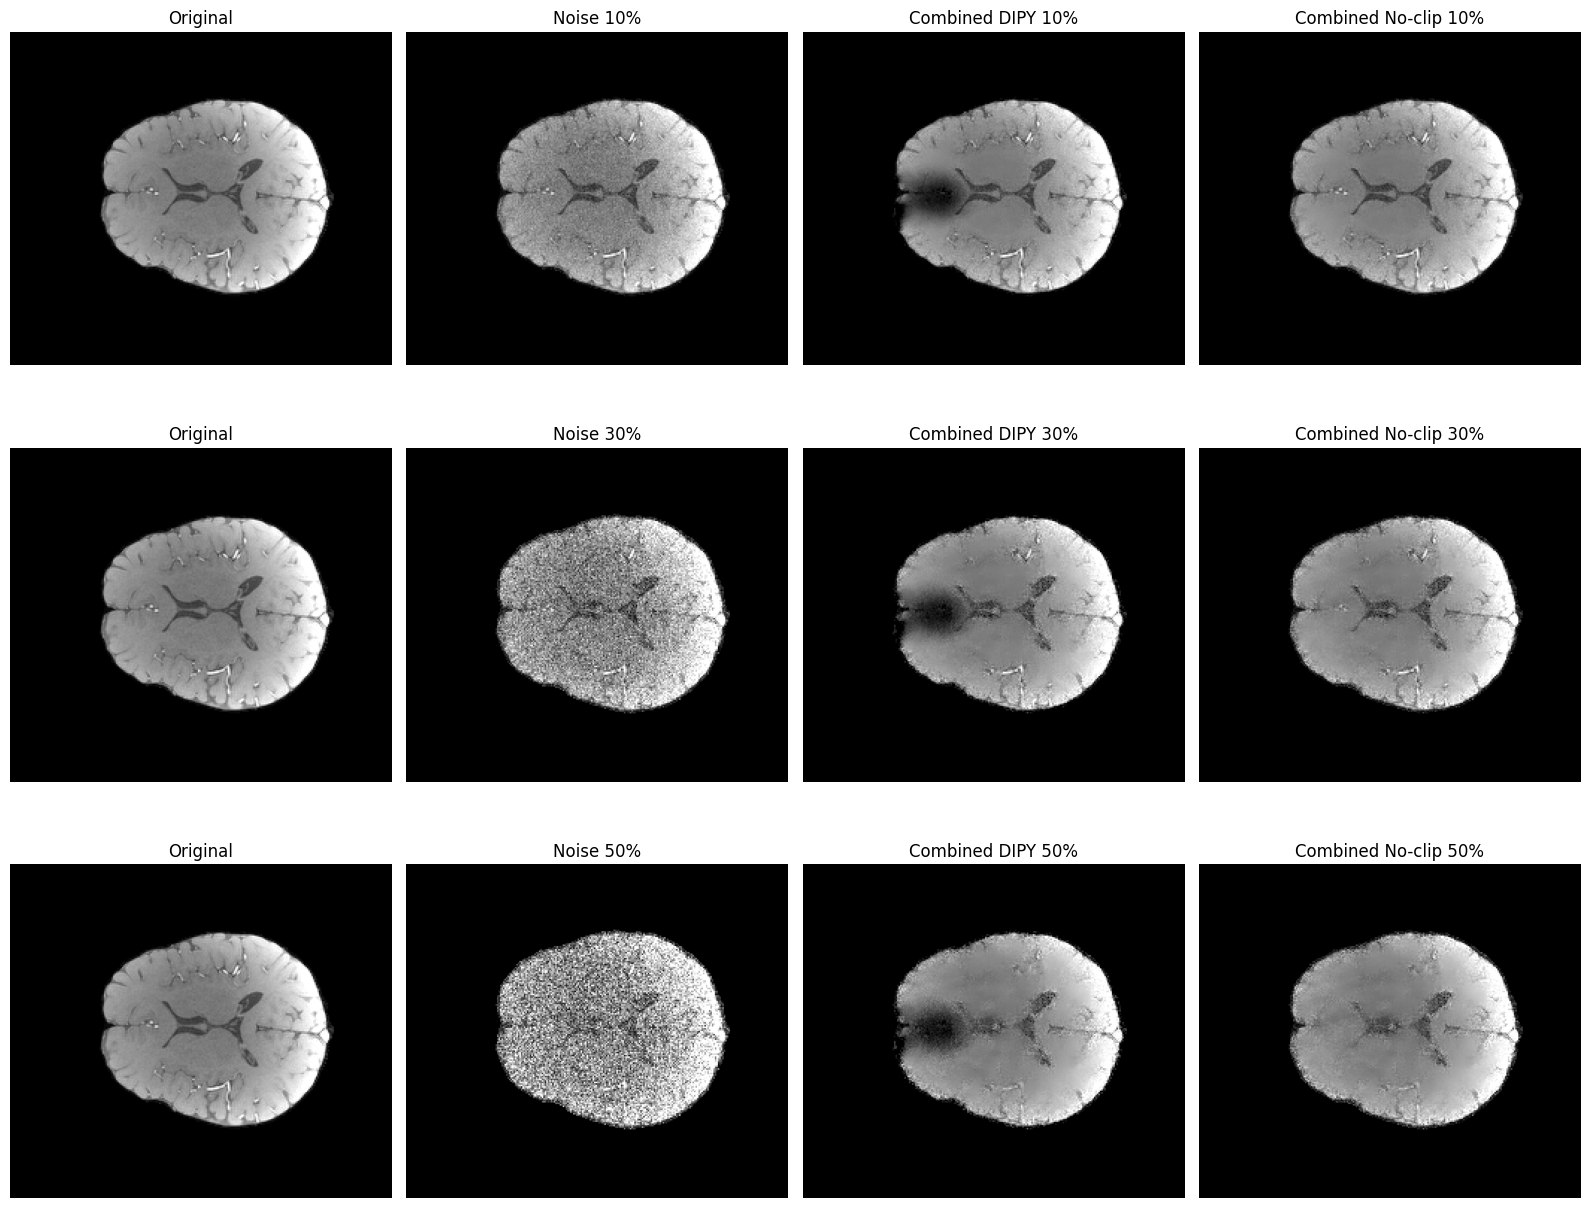

In [4]:
import os
import gc
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

os.chdir("/content/drive/MyDrive/MP-PCA")

# 원본
mat = sio.loadmat("meas_gre_dir1.mat")
meas_gre = mat["meas_gre"]

noise_levels = [10, 30, 50]

echo = 0
z = meas_gre.shape[2] // 2

original_slice = np.abs(
    meas_gre[:, :, z, echo]
)

vmin = np.percentile(original_slice, 1)
vmax = np.percentile(original_slice, 99)

fig, axes = plt.subplots(
    3, 4,
    figsize=(16, 13)
)

for row, level in enumerate(noise_levels):

    print(f"{level}% 처리 중...")

    # -------------------------
    # Noisy
    # -------------------------
    noise_mat = sio.loadmat(
        f"noisy_data/noisy_meas_gre_dir1_{level}.mat"
    )

    noisy_real = noise_mat["noisy_real"]
    noisy_imag = noise_mat["noisy_imag"]

    noisy_slice = np.sqrt(
        noisy_real[:, :, z, echo]**2
        +
        noisy_imag[:, :, z, echo]**2
    )

    # -------------------------
    # DIPY
    # -------------------------
    dipy_mat = sio.loadmat(
        f"denoised/combined_dipy_{level}.mat"
    )

    dipy = dipy_mat["combined_denoised"]

    dipy_slice = np.sqrt(
        dipy[:, :, z, echo]**2
        +
        dipy[:, :, z, echo + 6]**2
    )

    # -------------------------
    # No-clip
    # -------------------------
    noclip_mat = sio.loadmat(
        f"denoised/combined_noclip_{level}.mat"
    )

    noclip = noclip_mat["combined_denoised"]

    noclip_slice = np.sqrt(
        noclip[:, :, z, echo]**2
        +
        noclip[:, :, z, echo + 6]**2
    )

    images = [
        original_slice,
        noisy_slice,
        dipy_slice,
        noclip_slice
    ]

    titles = [
        "Original",
        f"Noise {level}%",
        f"Combined DIPY {level}%",
        f"Combined No-clip {level}%"
    ]

    for col in range(4):

        axes[row, col].imshow(
            images[col].T,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

    # 메모리 정리
    del noise_mat
    del noisy_real
    del noisy_imag
    del dipy_mat
    del dipy
    del noclip_mat
    del noclip

    gc.collect()

plt.tight_layout()

# -------------------------
# 이미지 저장
# -------------------------
os.makedirs("visualization", exist_ok=True)

save_path = (
    f"visualization/"
    f"combined_compare_echo{echo+1}_slice{z}_10_30_50.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print("이미지 저장 완료:")
print(save_path)

plt.show()